In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string



In [ ]:
df = pd.read_csv("Phishing_Email.csv")

In [3]:
df.head()

,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [4]:
df.columns
df.shape


(18650, 3)

In [5]:
df.isnull().sum()

Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

In [6]:
df = df.dropna(subset=["Email Text"])

In [7]:
df.isnull().sum()

Unnamed: 0    0
Email Text    0
Email Type    0
dtype: int64

In [10]:
df["Email Text"].duplicated().sum()

np.int64(1097)

In [11]:
df = df.drop_duplicates(subset=["Email Text"])

In [12]:
df.shape

(17537, 3)

In [14]:
df["Email Text"].duplicated().sum()

np.int64(0)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17537 entries, 0 to 18648
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  17537 non-null  int64 
 1   Email Text  17537 non-null  object
 2   Email Type  17537 non-null  object
dtypes: int64(1), object(2)
memory usage: 548.0+ KB


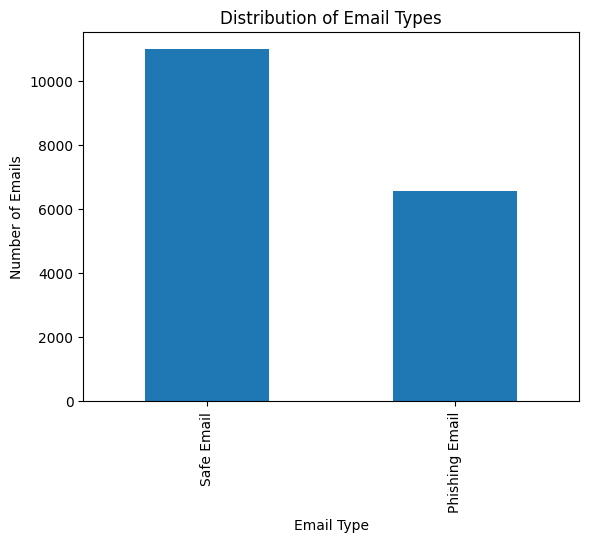

In [16]:
df["Email Type"].value_counts().plot(kind="bar")

plt.title("Distribution of Email Types")
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")
plt.show()

In [17]:
df.columns

Index(['Unnamed: 0', 'Email Text', 'Email Type'], dtype='object')

In [18]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [19]:
df.columns

Index(['Email Text', 'Email Type'], dtype='object')

In [20]:
df.isnull().sum()

Email Text    0
Email Type    0
dtype: int64

In [22]:
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (17537, 2)


In [25]:
def count_urls(text):
    return len(re.findall(r'https?://\S+|www\.\S+', str(text)))

df["url_count"] = df["Email Text"].apply(count_urls)

In [26]:
df["email_length"] = df["Email Text"].apply(
    lambda x: len(str(x))
)

In [29]:
df["exclamation_count"] = df["Email Text"].apply(
    lambda x: str(x).count("!")
)
df["question_count"] = df["Email Text"].apply(
    lambda x: str(x).count("?")
)
df["digit_count"] = df["Email Text"].apply(
    lambda x: sum(char.isdigit() for char in str(x))
)

In [33]:
def clean_text(text):

    text = str(text)

    # Convert to lowercas
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Replace URLs
    text = re.sub(r"http\S+|www\S+", " url ", text)

    # Replace email addresses
    text = re.sub(r"\S+@\S+", " email ", text)

    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [36]:
df["clean_text"] = df["Email Text"].apply(clean_text)

In [37]:
print("ORIGINAL EMAIL:\n")
print(df["Email Text"].iloc[0])

print("\n-----------------------------\n")

print("CLEANED EMAIL:\n")
print(df["clean_text"].iloc[0])

ORIGINAL EMAIL:

re : 6 . 1100 , disc : uniformitarianism , re : 1086 ; sex / lang dick hudson 's observations on us use of 's on ' but not 'd aughter ' as a vocative are very thought-provoking , but i am not sure that it is fair to attribute this to " sons " being " treated like senior relatives " . for one thing , we do n't normally use ' brother ' in this way any more than we do 'd aughter ' , and it is hard to imagine a natural class comprising senior relatives and 's on ' but excluding ' brother ' . for another , there seem to me to be differences here . if i am not imagining a distinction that is not there , it seems to me that the senior relative terms are used in a wider variety of contexts , e . g . , calling out from a distance to get someone 's attention , and hence at the beginning of an utterance , whereas 's on ' seems more natural in utterances like ' yes , son ' , ' hand me that , son ' than in ones like ' son ! ' or ' son , help me ! ' ( although perhaps these latter o

In [39]:
df["label"] = df["Email Type"].map({
    "Safe Email": 0,
    "Phishing Email": 1
})
df[["Email Type", "label"]].head()

,Email Type,label
0,Safe Email,0
1,Safe Email,0
2,Safe Email,0
3,Phishing Email,1
4,Phishing Email,1


In [40]:
df["label"].value_counts()

label
0    10979
1     6558
Name: count, dtype: int64

In [41]:
X = df["clean_text"]
y = df["label"]

In [42]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [43]:
print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 14029
Testing: 3508


In [44]:
from sklearn.feature_extraction.text import CountVectorizer
bow = CountVectorizer(
    max_features=5000,
    stop_words="english"
)

In [45]:
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

In [46]:
print(X_train_bow.shape)
print(X_test_bow.shape)

(14029, 5000)
(3508, 5000)


In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2)
)

In [50]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(14029, 10000)
(3508, 10000)


# first ML model logistic regression

In [51]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [52]:
lr_pred = lr.predict(
    X_test_tfidf
)

In [65]:
from sklearn.metrics import (accuracy_score , precision_score)
lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

print("Accuracy:", lr_accuracy)

Accuracy: 0.9774800456100342


In [54]:
from sklearn.metrics import classification_report
print(
    classification_report(
        y_test,
        lr_pred
    )
)

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2196
           1       0.98      0.96      0.97      1312

    accuracy                           0.98      3508
   macro avg       0.98      0.97      0.98      3508
weighted avg       0.98      0.98      0.98      3508



# naive bayes


In [57]:
from sklearn.naive_bayes import MultinomialNB

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [58]:
nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

MultinomialNB()

In [59]:
nb_pred = nb_model.predict(X_test_tfidf)

In [60]:
print(
    classification_report(
        y_test,
        nb_pred,
        target_names=["Safe Email", "Phishing Email"]
    )
)

                precision    recall  f1-score   support

    Safe Email       0.97      0.98      0.98      2196
Phishing Email       0.97      0.96      0.96      1312

      accuracy                           0.97      3508
     macro avg       0.97      0.97      0.97      3508
  weighted avg       0.97      0.97      0.97      3508



# Random forest

In [61]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf.fit(
    X_train_tfidf,
    y_train
)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [62]:
rf_pred = rf.predict(
    X_test_tfidf
)
rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.9723489167616876


In [63]:
print(
    classification_report(
        y_test,
        rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2196
           1       0.95      0.97      0.96      1312

    accuracy                           0.97      3508
   macro avg       0.97      0.97      0.97      3508
weighted avg       0.97      0.97      0.97      3508



In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [68]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, nb_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, nb_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, nb_pred),
        f1_score(y_test, rf_pred)
    ]
})

In [69]:
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.977480,0.979767,0.959604,0.969580
1,Naive Bayes,0.974059,0.974359,0.955793,0.964987
2,Random Forest,0.972349,0.954375,0.972561,0.963382


In [70]:
results = results.sort_values(
    by="Accuracy",
    ascending=False
)

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.977480,0.979767,0.959604,0.969580
1,Naive Bayes,0.974059,0.974359,0.955793,0.964987
2,Random Forest,0.972349,0.954375,0.972561,0.963382


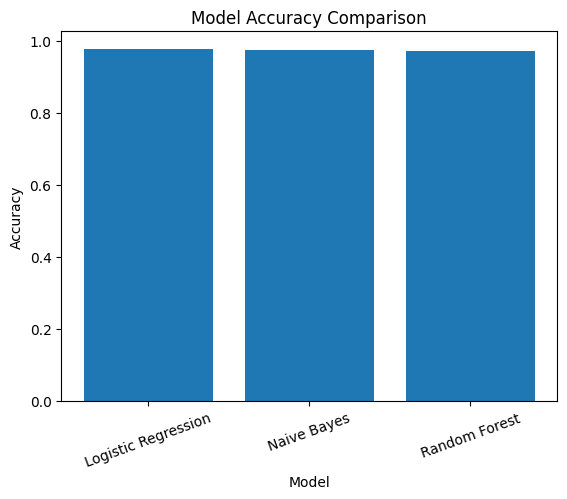

In [71]:
plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=20)

plt.show()

# Model deploymnet 

In [74]:
import joblib

joblib.dump(lr, "phishing_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [75]:
loaded_model = joblib.load("phishing_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

In [76]:
test_email = """
URGENT! Your account has been suspended.
Click https://fake-bank-example.com immediately
to verify your account.
"""

In [77]:
cleaned_email = clean_text(test_email)

print(cleaned_email)

urgent your account has been suspended click url immediately to verify your account


In [81]:
def predict_email(email_text):
    # Clean the email using the same preprocessing
    cleaned_email = clean_text(email_text)

    # Convert email text into TF-IDF features
    email_vector = tfidf.transform([cleaned_email])

    # Make prediction
    prediction = lr.predict(email_vector)[0]

    # Get probabilities
    probabilities = lr.predict_proba(email_vector)[0]

    safe_probability = probabilities[0] * 100
    phishing_probability = probabilities[1] * 100

    # Display result
    if prediction == 1:
        print("⚠️ Prediction: PHISHING EMAIL")
    else:
        print("✅ Prediction: SAFE EMAIL")

    print(f"Safe Probability: {safe_probability:.2f}%")
    print(f"Phishing Probability: {phishing_probability:.2f}%")

In [82]:
predict_email("""
URGENT! Your bank account has been suspended.

Click the link below immediately to verify your identity:
https://verify-account-example.com

Failure to verify your account within 24 hours will result
in permanent suspension.
""")

⚠️ Prediction: PHISHING EMAIL
Safe Probability: 4.15%
Phishing Probability: 95.85%


In [83]:
predict_email("""
Hi John,

The project meeting has been scheduled for Monday at 11 AM.
Please bring the latest project report.

Thanks,
David
""")

✅ Prediction: SAFE EMAIL
Safe Probability: 98.09%
Phishing Probability: 1.91%
